# Learning from chronological sequence data

A financial sequence of length $T$ is written as $X_{1:T}=(X_1,\ldots,X_T)$. Its joint distribution can be separated into conditional transition distributions:

$$
p(x_{1:T})=p(x_1)\prod_{t=2}^{T}p(x_t\mid x_{1:t-1}).
$$

Here, $X_t$ is the vector observed at time $t$; $x_t$ is one possible value of that vector; $x_{1:t-1}$ is the preceding history; $p(x_{1:T})$ is the joint density or mass function of the whole sequence. Each factor $p(x_t\mid x_{1:t-1})$ describes the next observation given the earlier observations. A useful generator must therefore represent both the marginal values and their order through time.

## Public Daily Market Data

The first feature is the daily continuously compounded return in percent:

$$
r_t=100\log\!\left(\frac{P_t}{P_{t-1}}\right).
$$

Here, $P_t$ and $P_{t-1}$ are consecutive valid NASDAQ Composite closing levels, and $r_t$ is the return from the preceding close to the current close. The factor $100$ expresses the result in percentage points.

The second feature is the sample standard deviation of the latest twenty returns:

$$
v_t=\left[\frac{1}{19}\sum_{j=0}^{19}\left(r_{t-j}-\bar r_t\right)^2\right]^{1/2},
\qquad
\bar r_t=\frac{1}{20}\sum_{j=0}^{19}r_{t-j}.
$$

Here, $v_t$ is the twenty-day return volatility; $\bar r_t$ is the mean of the same twenty returns; $j$ counts backward from the current date. The denominator is $19$ because the calculation uses the sample standard deviation of twenty observations.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("03_generative_financial_time_series");
using CSV, TOML
artifacts = joinpath(book_root(), "outputs", "julia", "artifacts", "03_generative_financial_time_series")
mkpath(artifacts)

function save_tensor(name, values)
    CSV.write(joinpath(artifacts, name*".csv"), DataFrame(Value=vec(values)))
    open(joinpath(artifacts, name*".toml"), "w") do stream
        TOML.print(stream, Dict("shape"=>collect(size(values)), "storage_order"=>"column-major"))
    end
    return nothing
end

function load_tensor(name)
    shape = TOML.parsefile(joinpath(artifacts, name*".toml"))["shape"]
    values = CSV.read(joinpath(artifacts, name*".csv"), DataFrame).Value
    return reshape(Float64.(values), Tuple(shape))
end

pack_parameters(values::NamedTuple) = Dict(string(key)=>pack_parameters(getproperty(values, key)) for key in keys(values))
pack_parameters(values::AbstractArray) = Dict("shape"=>collect(size(values)), "values"=>vec(values))

function unpack_parameters(template::NamedTuple, saved)
    return NamedTuple{keys(template)}(Tuple(unpack_parameters(getproperty(template, key), saved[string(key)]) for key in keys(template)))
end

function unpack_parameters(template::AbstractArray, saved)
    @assert Tuple(saved["shape"]) == size(template)
    return reshape(Float64.(saved["values"]), size(template))
end

function save_parameters(name, parameters)
    open(joinpath(artifacts, name*".toml"), "w") do stream
        TOML.print(stream, pack_parameters(parameters))
    end
    return nothing
end


save_parameters (generic function with 1 method)

In [2]:
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path, DataFrame; missingstring=["", "."])
valid = dropmissing(raw, :NASDAQCOM)
sort!(valid, :observation_date)
rename!(valid, :observation_date=>"Date", :NASDAQCOM=>"NASDAQ Composite")
valid[!, "Date"] = Date.(valid[!, "Date"])
levels = Float64.(valid[!, "NASDAQ Composite"])
returns = vcat(NaN, 100 .* log.(levels[2:end]./levels[1:end-1]))
volatility = [index>=21 ? std(returns[index-19:index]) : NaN for index in eachindex(returns)]
valid[!, "Daily log return (%)"] = returns
valid[!, "Twenty-day return volatility (%)"] = volatility
features = valid[isfinite.(returns).&isfinite.(volatility), :]
window_length = 20
training_end = floor(Int, .8*nrow(features))
split_date = features[training_end+1, "Date"]
feature_names = ["Daily log return (%)", "Twenty-day return volatility (%)"]
provenance = DataFrame("Item"=>["Series", "Provider", "Source institution", "Frequency", "Local period", "Download during run"], "Value"=>["NASDAQ Composite (NASDAQCOM)", "Federal Reserve Economic Data", "Nasdaq, Inc.", "Daily close", string(first(valid[!, "Date"]), " to ", last(valid[!, "Date"])), "No"])
save_table(provenance, paths, "data_provenance"; caption="Public data and fixed local file identity.", label="tab:chapter4-generative-data-provenance")
split_summary = DataFrame("Segment"=>["Training", "Held-out"], "First date"=>[features[1,"Date"], split_date], "Last date"=>[features[training_end,"Date"], features[end,"Date"]], "Observations"=>[training_end,nrow(features)-training_end], "Windows"=>[training_end-window_length+1,nrow(features)-training_end-window_length+1])
save_table(split_summary, paths, "chronological_split"; caption="Chronological training and held-out segments.", label="tab:chapter4-chronological-split")
summary_rows = NamedTuple[]
for (segment, part) in [("Training",features[1:training_end,:]), ("Held-out",features[training_end+1:end,:])], feature in feature_names
    values = part[!,feature]
    push!(summary_rows, (;segment,feature,average=mean(values),deviation=std(values),minimum=minimum(values),median=median(values),maximum=maximum(values)))
end
feature_summary = DataFrame(summary_rows)
rename!(feature_summary,["Segment","Feature","Mean","Standard deviation","Minimum","Median","Maximum"])
save_table(feature_summary, paths, "feature_summary"; caption="Summary of the two public data features by chronological segment.", label="tab:chapter4-feature-summary")
public_series = copy(valid)
public_series.Segment = ifelse.(public_series[!,"Date"].<split_date,"Training","Held-out")
save_data(public_series, paths, "public_series")
display(first(features,5))


Row,Item,Value
,String,String
1,Series,NASDAQ Composite (NASDAQCOM)
2,Provider,Federal Reserve Economic Data
3,Source institution,"Nasdaq, Inc."
4,Frequency,Daily close
5,Local period,1994-01-03 to 2025-12-31
6,Download during run,No


Row,Segment,First date,Last date,Observations,Windows
,String,Date,Date,Int64,Int64
1,Training,1994-01-31,2019-08-09,6428,6409
2,Held-out,2019-08-12,2025-12-31,1607,1588


Row,Segment,Feature,Mean,Standard deviation,Minimum,Median,Maximum
,String,String,Float64,Float64,Float64,Float64,Float64
1,Training,Daily log return (%),0.0358091,1.51531,-10.1684,0.110491,13.2546
2,Training,Twenty-day return volatility (%),1.29686,0.790706,0.342005,1.05728,5.50527
3,Held-out,Daily log return (%),0.0666857,1.56119,-13.1492,0.142295,11.4784
4,Held-out,Twenty-day return volatility (%),1.37462,0.762798,0.444383,1.21416,6.01654


Row,Date,NASDAQ Composite,Daily log return (%),Twenty-day return volatility (%)
,Date,Float64,Float64,Float64
1,1994-01-31,800.47,0.493426,0.351161
2,1994-02-01,797.24,-0.404329,0.369004
3,1994-02-02,799.57,0.291832,0.362094
4,1994-02-03,797.79,-0.222868,0.368403
5,1994-02-04,777.28,-2.60448,0.706119


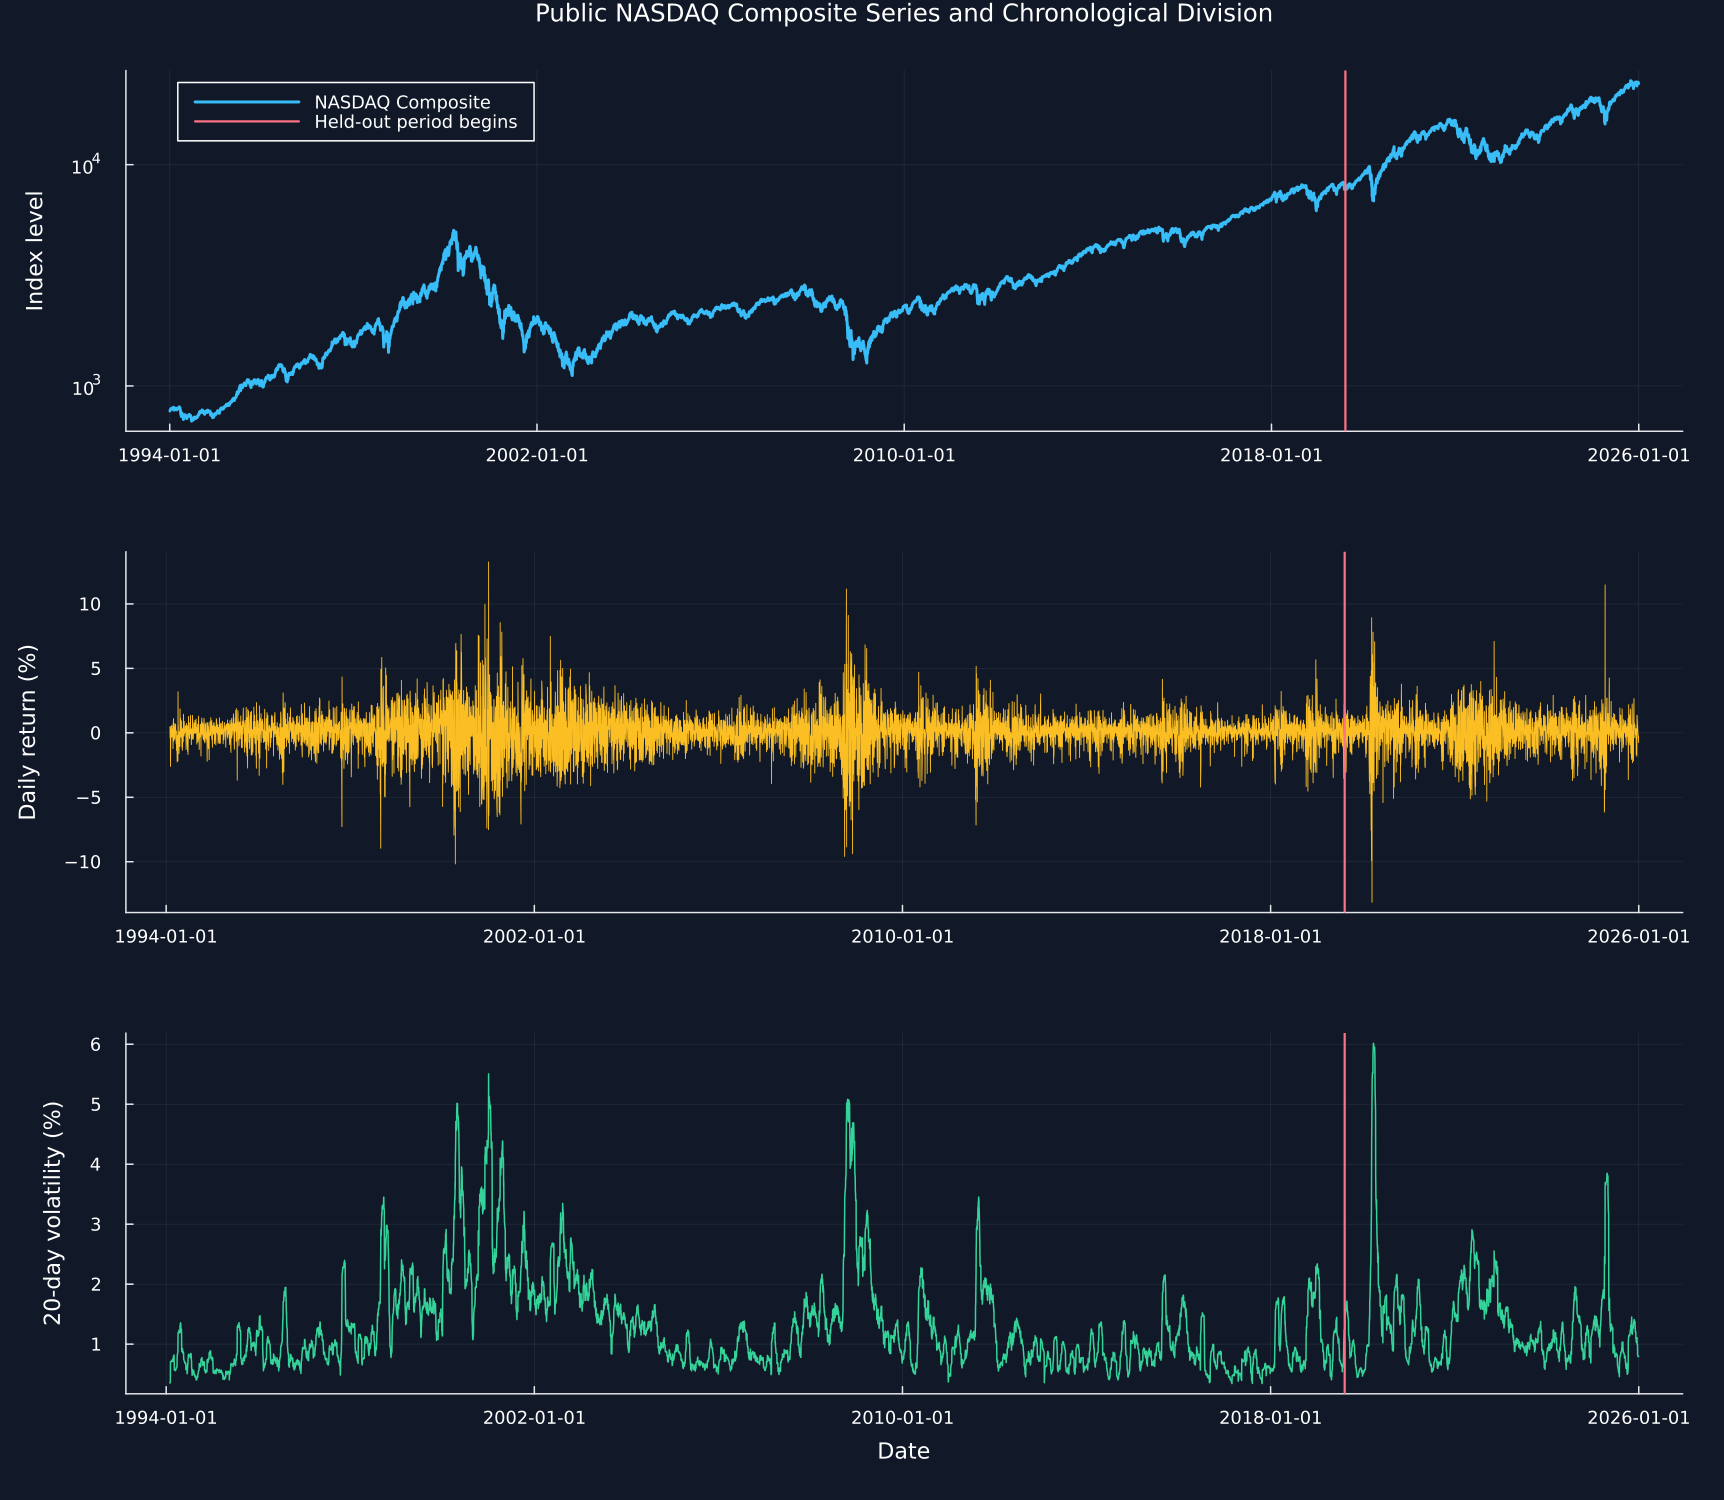

In [3]:
panels = [plot(valid[!,"Date"], levels; yscale=:log10, color=palette.cyan, ylabel="Index level", title="Public NASDAQ Composite Series and Chronological Division", label="NASDAQ Composite"),
    plot(features[!,"Date"], features[!,feature_names[1]]; color=palette.amber, linewidth=.6, ylabel="Daily return (%)", label=false),
    plot(features[!,"Date"], features[!,feature_names[2]]; color=palette.green, linewidth=1, ylabel="20-day volatility (%)", xlabel="Date", label=false)]
for (index, panel) in enumerate(panels)
    vline!(panel,[split_date];color=palette.rose,linewidth=1.5,label=index==1 ? "Held-out period begins" : false)
end
plot!(panels[1];legend=:topleft)
save_figure(plot(panels...;layout=(3,1),size=(1150,1000)),paths,"public_series_split")


## Chronological Separation Before Windowing

For a feature sequence $X_1,\ldots,X_n$ and window length $w$, the $i$th window is

$$
W_i=(X_i,X_{i+1},\ldots,X_{i+w-1}),
\qquad i=1,\ldots,n-w+1.
$$

Here, $X_t\in\mathbb R^d$ contains the $d$ features observed on date $t$; $w$ is the number of dates in one window; $W_i\in\mathbb R^{w\times d}$ is the window beginning at observation $i$. The chronological boundary is applied before this formula, so no training window contains a held-out date and no held-out window contains a training date.

Each feature is scaled with training data only:

$$
Z_{t,j}=\frac{X_{t,j}-a_j}{b_j},
\qquad
a_j=\min_{t\in\mathcal T}X_{t,j},
\qquad
b_j=\max_{t\in\mathcal T}X_{t,j}-a_j.
$$

Here, $j$ identifies a feature; $\mathcal T$ is the set of training dates; $a_j$ is the training minimum; $b_j$ is the training range; $Z_{t,j}$ is the scaled value. Held-out values are not used to find $a_j$ or $b_j$, and they are not clipped when they lie outside the training range.

In [4]:
feature_array = Matrix{Float64}(features[:,feature_names])
prepared = RiskLabAI.Data.chronological_timegan_data(feature_array;training_end,window_length)
training_windows, validation_windows = prepared.training, prepared.validation
minimum_values, scale = prepared.minimum, prepared.scale
@assert size(training_windows) == (6409,20,2)
@assert size(validation_windows) == (1588,20,2)
@assert all(0 .<= training_windows .<= 1)
@assert training_windows[end,:,:].*scale'.+minimum_values' ≈ feature_array[training_end-window_length+1:training_end,:]
@assert validation_windows[1,:,:].*scale'.+minimum_values' ≈ feature_array[training_end+1:training_end+window_length,:]
save_tensor("training_windows",training_windows)
save_tensor("validation_windows",validation_windows)
open(joinpath(artifacts,"prepared_metadata.toml"),"w") do stream
    TOML.print(stream,Dict("minimum"=>minimum_values,"scale"=>scale,"feature_names"=>feature_names,"dates"=>string.(features[!,"Date"]),"training_end"=>training_end,"window_length"=>window_length))
end
scaling_table = DataFrame("Feature"=>feature_names,"Training minimum"=>minimum_values,"Training maximum"=>minimum_values.+scale,"Training range"=>scale,"Held-out scaled minimum"=>[minimum(validation_windows[:,:,j]) for j in 1:2],"Held-out scaled maximum"=>[maximum(validation_windows[:,:,j]) for j in 1:2])
save_table(scaling_table,paths,"training_scaling";caption="Training-only scaling and held-out ranges.",label="tab:chapter4-training-scaling")
scaled_full = (feature_array.-minimum_values')./scale'
scaled_series = DataFrame("Date"=>features[!,"Date"],"Scaled daily return"=>scaled_full[:,1],"Scaled twenty-day volatility"=>scaled_full[:,2],"Segment"=>ifelse.((1:nrow(features)).<=training_end,"Training","Held-out"))
save_data(scaled_series,paths,"scaled_feature_series")
window_rows = NamedTuple[]
for (name,window) in [("Last training window",training_windows[end,:,:]),("First held-out window",validation_windows[1,:,:])], day in 1:window_length, (j,feature) in enumerate(feature_names)
    push!(window_rows,(;window=name,day,feature,value=window[day,j]))
end
window_frame = DataFrame(window_rows)
rename!(window_frame,["Window","Relative day","Feature","Scaled value"])
save_data(window_frame,paths,"chronological_window_examples");


Row,Feature,Training minimum,Training maximum,Training range,Held-out scaled minimum,Held-out scaled maximum
,String,Float64,Float64,Float64,Float64,Float64
1,Daily log return (%),-10.1684,13.2546,23.4231,-0.127257,0.924169
2,Twenty-day return volatility (%),0.342005,5.50527,5.16326,0.0198283,1.09902


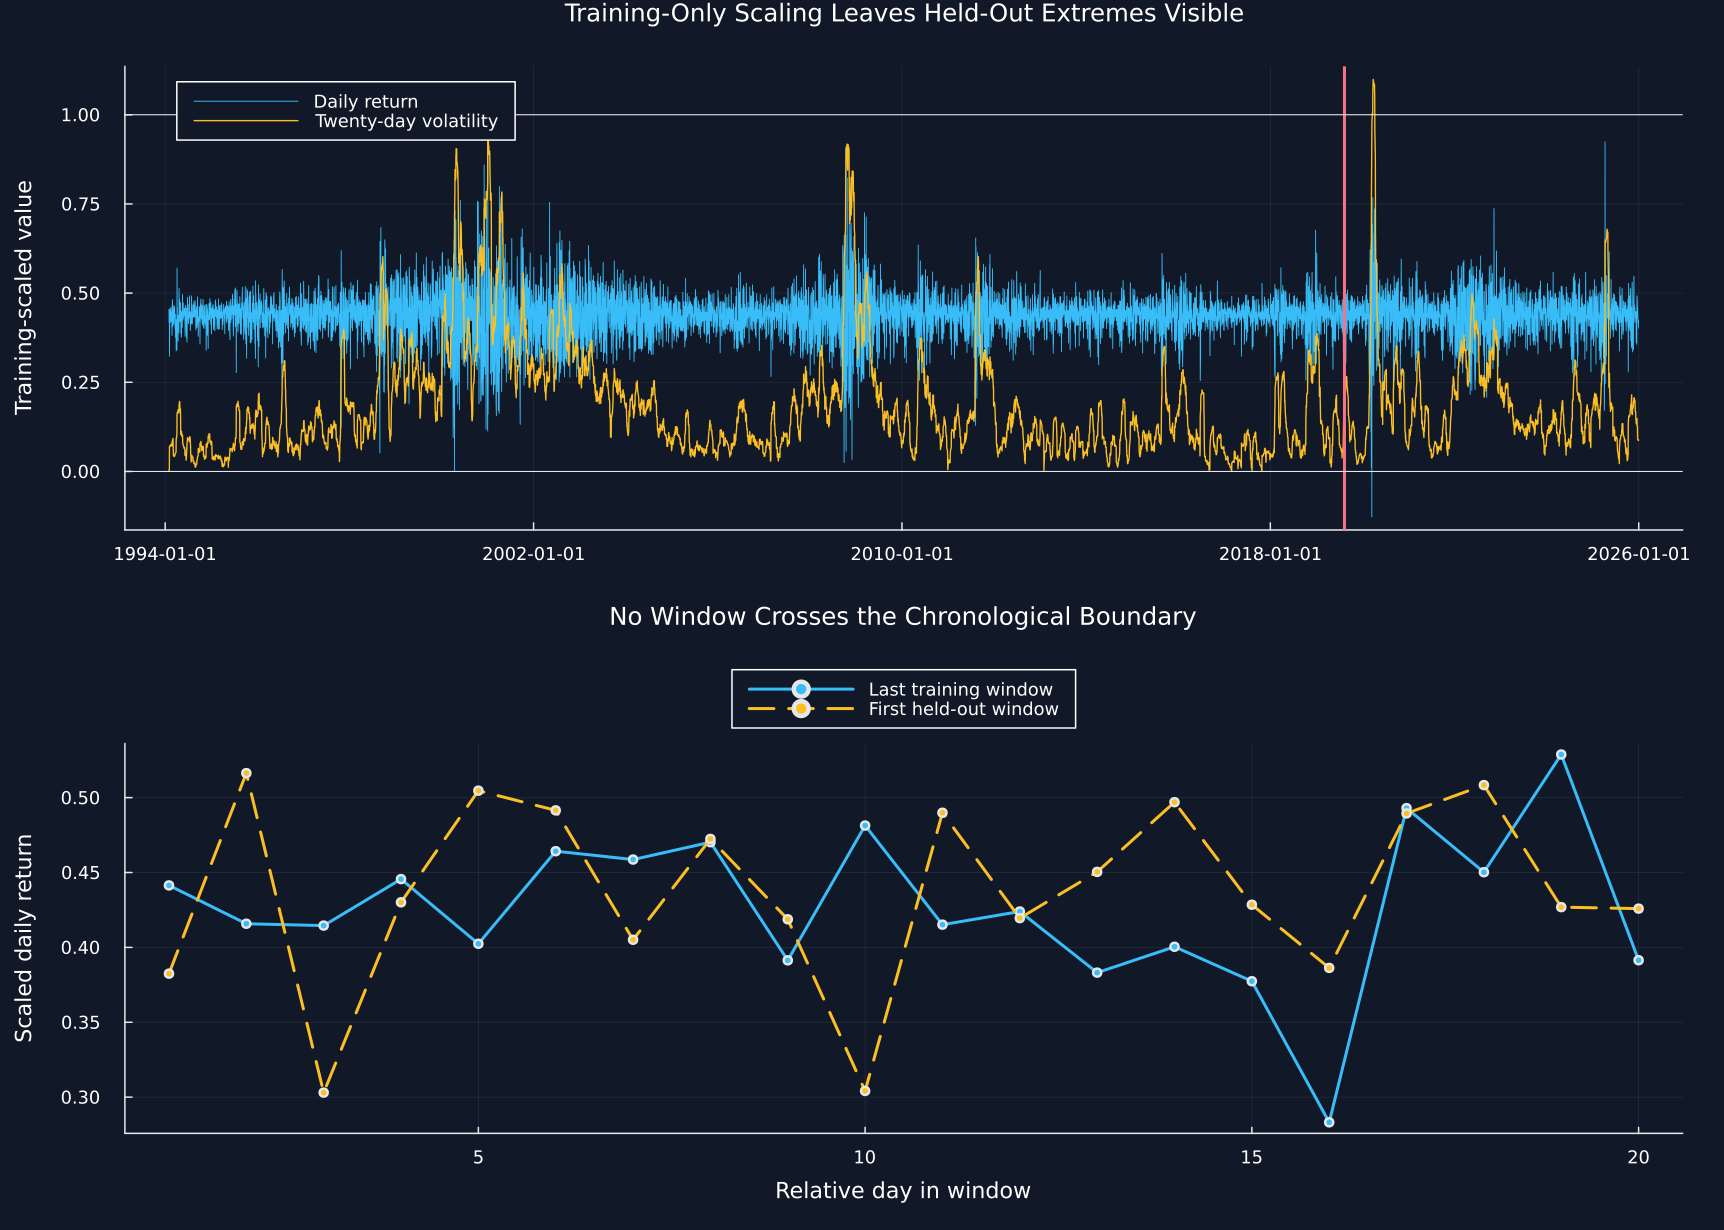

In [5]:
top = plot(scaled_series.Date,scaled_series[!,"Scaled daily return"];color=palette.cyan,linewidth=.6,label="Daily return",ylabel="Training-scaled value",title="Training-Only Scaling Leaves Held-Out Extremes Visible",legend=:topleft)
plot!(top,scaled_series.Date,scaled_series[!,"Scaled twenty-day volatility"];color=palette.amber,linewidth=.9,label="Twenty-day volatility")
vline!(top,[split_date];color=palette.rose,label=false)
hline!(top,[0,1];color=palette.text,linewidth=.7,label=false)
bottom = plot(;xlabel="Relative day in window",ylabel="Scaled daily return",title="No Window Crosses the Chronological Boundary",legend=:outertop)
for (name,color,style) in [("Last training window",palette.cyan,:solid),("First held-out window",palette.amber,:dash)]
    part = window_frame[(window_frame.Window.==name).&(window_frame.Feature.==feature_names[1]),:]
    plot!(bottom,part[!,"Relative day"],part[!,"Scaled value"];color,linestyle=style,marker=:circle,markersize=3,label=name)
end
save_figure(plot(top,bottom;layout=(2,1),size=(1150,820)),paths,"scaling_and_windows")


## Tests

In [6]:
toy = hcat(0.:19.,ones(20))
toy_result = RiskLabAI.Data.chronological_timegan_data(toy;training_end=12,window_length=4)
@assert toy_result.minimum ≈ [0,1]
@assert toy_result.scale ≈ [11,1]
@assert toy_result.training[end,:,:].*toy_result.scale'.+toy_result.minimum' ≈ toy[9:12,:]
@assert toy_result.validation[1,:,:].*toy_result.scale'.+toy_result.minimum' ≈ toy[13:16,:]
changed = copy(toy)
changed[13:end,:] .*= 100
altered = RiskLabAI.Data.chronological_timegan_data(changed;training_end=12,window_length=4)
@assert toy_result.training ≈ altered.training
@assert toy_result.scale ≈ altered.scale
checks = DataFrame("Check"=>["Public file identity","Training windows","Held-out windows","Training values in unit interval","Boundary reconstruction","Held-out changes leave training scaling unchanged"],"Result"=>fill("Pass",6))
save_table(checks,paths,"chronology_checks";caption="Checks for public data identity, scaling, and chronological window construction.",label="tab:chapter4-chronology-checks")


Row,Check,Result
,String,String
1,Public file identity,Pass
2,Training windows,Pass
3,Held-out windows,Pass
4,Training values in unit interval,Pass
5,Boundary reconstruction,Pass
6,Held-out changes leave training scaling unchanged,Pass
